### Q4 In which brain area are pairwise spike train interactions strongest at the 100 ms timescale?

Pairwise interactions are quantified with the Spike Time Tiling Coefficient (STTC), using `dt = 100 ms`. The complete spike trains are used. Every unordered pair of simultaneously recorded units is included within each mouse × brain-area group; units are never paired across mice or across brain areas.

Spike timestamps and recording bounds are kept as floating-point seconds, so the 100-ms STTC half-window is passed as `dt = 0.1`; timestamps are not rounded to integer seconds or samples. The exported dataset contains an LFP-derived recording duration but not a recording-clock start. The observation window for each mouse is therefore anchored at that mouse's earliest observed spike and extends for the full LFP-derived duration. This retains all spikes, including valid negative timestamps from an offset spike clock. Pair-level values are saved for downstream statistics. Descriptive area summaries use each mouse × area mean as the observational unit so that areas with more recorded units (and  more pairs) do not dominate the area mean.

In [1]:
import csv
import os
import pickle
import sys
import tempfile
import time
from collections import defaultdict
from datetime import datetime
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

#### Parameters

In [2]:
project_folder = Path("E:/con2phys_submission")
sua_csv_path = project_folder / "dataset" / "full_sua_dataset.csv"
isttc_repo_path = Path("D:/intr_timescales/isttc")
q_path = Path(os.environ.get(
    "Q4_OUTPUT_DIR", "D:/git_repos/con2phys_submission/results/q4"
))
results_csv_path = q_path / "sttc_pairs_100ms.csv"
mouse_area_csv_path = q_path / "sttc_mouse_area_100ms.csv"
area_summary_csv_path = q_path / "sttc_area_100ms.csv"
run_log_path = q_path / "sttc_run_times.csv"
figure_path = q_path / "sttc_100ms_by_brain_area.png"

STTC_DT_SECONDS = 0.100
EXPECTED_N_MICE = 18
EXPECTED_N_UNITS = 1_449
EXPECTED_BRAIN_AREAS = (1, 2, 3)
EXPECTED_N_GROUPS = EXPECTED_N_MICE * len(EXPECTED_BRAIN_AREAS)
EXPECTED_N_PAIRS = 25_299
DURATION_ATOL_SECONDS = 1e-9
MAX_GROUPS = (
    int(os.environ["Q4_MAX_GROUPS"])
    if os.environ.get("Q4_MAX_GROUPS")
    else None
)

isttc_src_path = isttc_repo_path / "src"
if str(isttc_src_path) not in sys.path:
    sys.path.insert(0, str(isttc_src_path))

from isttc.scripts.calculate_acf import (
    sttc, sttc_calculate_p_fast, sttc_calculate_t_fast,
)

RUN_CONFIG = {
    "method": "plain_pairwise_sttc",
    "sttc_dt_seconds": STTC_DT_SECONDS,
    "pairing": "all_unordered_pairs_within_mouse_and_brain_area",
    "signal": "complete_recording",
    "recording_bounds": "earliest_mouse_spike_to_origin_plus_lfp_duration",
    "max_groups": MAX_GROUPS,
}
RUN_CONFIG

{'method': 'plain_pairwise_sttc',
 'sttc_dt_seconds': 0.1,
 'pairing': 'all_unordered_pairs_within_mouse_and_brain_area',
 'signal': 'complete_recording',
 'recording_bounds': 'earliest_mouse_spike_to_origin_plus_lfp_duration',
 'max_groups': None}

#### Load and validate complete spike trains

The source CSV is streamed one row at a time so that the large spike strings are not retained alongside their parsed arrays. Recording duration must be common to all units from a mouse. Because the source does not store the recording-clock start, each mouse's earliest observed spike is used as the common window origin and the LFP-derived duration defines its length. The observed spike span is required to fit inside this window.

In [3]:
required_paths = [sua_csv_path, isttc_src_path]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(f"Required paths not found: {missing_paths}")

expected_columns = [
    "mouse_id", "cluster_id", "brain_area",
    "recording_duration_sec", "unit_last_spike_sec",
    "n_spikes", "spikes",
]
units_by_group = defaultdict(list)
durations_by_mouse = defaultdict(list)
minimum_spike_by_mouse = defaultdict(lambda: np.inf)
maximum_spike_by_mouse = defaultdict(lambda: -np.inf)
unit_keys = set()

csv.field_size_limit(2**31 - 1)
with sua_csv_path.open(newline="", encoding="utf-8") as handle:
    reader = csv.DictReader(handle)
    if reader.fieldnames != expected_columns:
        raise ValueError(f"Unexpected SUA schema: {reader.fieldnames}")
    for source_index, row in enumerate(reader):
        mouse_id = int(row["mouse_id"])
        cluster_id = int(row["cluster_id"])
        brain_area = int(row["brain_area"])
        duration = float(row["recording_duration_sec"])
        expected_n_spikes = int(row["n_spikes"])
        spike_times = np.fromstring(row["spikes"], sep=";", dtype=np.float64)
        unit_key = (mouse_id, cluster_id)

        if unit_key in unit_keys:
            raise ValueError(f"Duplicate unit key: {unit_key}")
        if brain_area not in EXPECTED_BRAIN_AREAS:
            raise ValueError(f"Unexpected brain area for {unit_key}: {brain_area}")
        if not np.isfinite(duration) or duration <= 0:
            raise ValueError(f"Invalid recording duration for {unit_key}: {duration}")
        if spike_times.size != expected_n_spikes or spike_times.size == 0:
            raise ValueError(f"Spike-count mismatch for {unit_key}")
        if not np.isfinite(spike_times).all() or np.any(np.diff(spike_times) < 0):
            raise ValueError(f"Non-finite or unsorted spike times for {unit_key}")

        units_by_group[(mouse_id, brain_area)].append({
            "source_index": source_index,
            "mouse_id": mouse_id,
            "cluster_id": cluster_id,
            "brain_area": brain_area,
            "recording_duration_sec": duration,
            "n_spikes": expected_n_spikes,
            "spikes": spike_times,
        })
        durations_by_mouse[mouse_id].append(duration)
        minimum_spike_by_mouse[mouse_id] = min(
            minimum_spike_by_mouse[mouse_id], float(spike_times[0])
        )
        maximum_spike_by_mouse[mouse_id] = max(
            maximum_spike_by_mouse[mouse_id], float(spike_times[-1])
        )
        unit_keys.add(unit_key)

if len(unit_keys) != EXPECTED_N_UNITS:
    raise ValueError(f"Expected {EXPECTED_N_UNITS:,} units, found {len(unit_keys):,}")
if len(durations_by_mouse) != EXPECTED_N_MICE:
    raise ValueError(f"Expected {EXPECTED_N_MICE} mice, found {len(durations_by_mouse)}")
if len(units_by_group) != EXPECTED_N_GROUPS:
    raise ValueError(f"Expected {EXPECTED_N_GROUPS} mouse-area groups, found {len(units_by_group)}")

recording_duration_by_mouse = {}
for mouse_id, durations in durations_by_mouse.items():
    durations = np.asarray(durations, dtype=float)
    if not np.allclose(durations, durations[0], rtol=0, atol=DURATION_ATOL_SECONDS):
        raise ValueError(f"Recording duration differs between units for mouse {mouse_id}")
    recording_duration_by_mouse[mouse_id] = float(durations[0])

recording_start_by_mouse = dict(minimum_spike_by_mouse)
recording_stop_by_mouse = {
    mouse_id: recording_start_by_mouse[mouse_id] + duration
    for mouse_id, duration in recording_duration_by_mouse.items()
}
for mouse_id in sorted(recording_duration_by_mouse):
    if maximum_spike_by_mouse[mouse_id] > recording_stop_by_mouse[mouse_id]:
        raise ValueError(
            f"Observed spike span exceeds LFP duration for mouse {mouse_id}: "
            f"max spike={maximum_spike_by_mouse[mouse_id]}, "
            f"window stop={recording_stop_by_mouse[mouse_id]}"
        )

group_summary = pd.DataFrame([
    {
        "mouse_id": mouse_id,
        "brain_area": brain_area,
        "n_units": len(units),
        "n_pairs": len(units) * (len(units) - 1) // 2,
        "recording_duration_sec": recording_duration_by_mouse[mouse_id],
        "recording_start_sec": recording_start_by_mouse[mouse_id],
        "recording_stop_sec": recording_stop_by_mouse[mouse_id],
    }
    for (mouse_id, brain_area), units in sorted(units_by_group.items())
])
if int(group_summary["n_pairs"].sum()) != EXPECTED_N_PAIRS:
    raise ValueError(
        f"Expected {EXPECTED_N_PAIRS:,} pairs, found {int(group_summary['n_pairs'].sum()):,}"
    )
display(group_summary)
print(
    f"Validated {len(unit_keys):,} units in {len(units_by_group)} groups: "
    f"{int(group_summary['n_pairs'].sum()):,} within-group pairs."
)

,mouse_id,brain_area,n_units,n_pairs,recording_duration_sec,recording_start_sec,recording_stop_sec
0,1,1,59,1711,3350.972,0.043605,3351.015605
1,1,2,22,231,3350.972,0.043605,3351.015605
2,1,3,7,21,3350.972,0.043605,3351.015605
3,2,1,40,780,4655.478,-6.444758,4649.033242
4,2,2,20,190,4655.478,-6.444758,4649.033242
5,2,3,19,171,4655.478,-6.444758,4649.033242
6,3,1,47,1081,4102.642,0.006403,4102.648403
7,3,2,26,325,4102.642,0.006403,4102.648403
8,3,3,12,66,4102.642,0.006403,4102.648403
9,4,1,34,561,3934.196,0.003480,3934.199480


Validated 1,449 units in 54 groups: 25,299 within-group pairs.


#### Plain STTC calculation

`isttc.sttc()` recalculates the tiled-time terms for both units on every pair. Within a mouse, `dt`, `t_start`, and `t_stop` are fixed, so those terms can be calculated once per unit. The function below uses the package's vectorized `sttc_calculate_p_fast` and `sttc_calculate_t_fast` helpers and the exact branch logic/formula from `sttc()`. This changes only computation time, not the coefficient.

In [4]:
def atomic_pickle_dump(payload, destination: Path) -> None:
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = None
    try:
        with tempfile.NamedTemporaryFile(
            mode="wb", dir=destination.parent,
            prefix=f"{destination.stem}_", suffix=".tmp", delete=False,
        ) as handle:
            temporary_path = Path(handle.name)
            pickle.dump(payload, handle, protocol=pickle.HIGHEST_PROTOCOL)
        temporary_path.replace(destination)
    except Exception:
        if temporary_path is not None:
            temporary_path.unlink(missing_ok=True)
        raise


def atomic_csv_write(dataframe: pd.DataFrame, destination: Path) -> None:
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = destination.with_suffix(destination.suffix + ".tmp")
    try:
        dataframe.to_csv(temporary_path, index=False)
        temporary_path.replace(destination)
    except Exception:
        temporary_path.unlink(missing_ok=True)
        raise


def sttc_with_cached_t(spikes_a, spikes_b, dt, t_a, t_b):
    """Plain STTC using cached tiled-time proportions and fast package P terms."""
    n_a, n_b = len(spikes_a), len(spikes_b)
    if n_a == 0 or n_b == 0:
        return 0.0

    p_a = sttc_calculate_p_fast(spikes_a, spikes_b, n_a, n_b, dt) / n_a
    p_b = sttc_calculate_p_fast(spikes_b, spikes_a, n_b, n_a, dt) / n_b

    if t_a * p_b == 1 and t_b * p_a == 1:
        return 1.0
    if t_a * p_b == 1:
        return 0.5 * (p_a - t_b) / (1 - p_a * t_b) + 0.5
    if t_b * p_a == 1:
        return 0.5 + 0.5 * (p_b - t_a) / (1 - p_b * t_a)
    return (
        0.5 * (p_a - t_b) / (1 - p_a * t_b)
        + 0.5 * (p_b - t_a) / (1 - p_b * t_a)
    )


# Confirm equivalence to the package's reference sttc() before touching the data.
validation_trains = [
    np.array([0.05, 0.25, 0.70, 1.40, 2.80]),
    np.array([0.10, 0.30, 0.85, 1.35, 2.50]),
    np.array([0.02, 0.50, 0.90, 1.80, 2.95]),
]
validation_stop = 3.0
validation_t = [
    sttc_calculate_t_fast(train, len(train), STTC_DT_SECONDS, 0.0, validation_stop)[1]
    for train in validation_trains
]
for i, j in combinations(range(len(validation_trains)), 2):
    reference = sttc(
        validation_trains[i], validation_trains[j],
        t_start_=0.0, t_stop_=validation_stop, dt_=STTC_DT_SECONDS,
        verbose_=False,
    )
    optimized = sttc_with_cached_t(
        validation_trains[i], validation_trains[j], STTC_DT_SECONDS,
        validation_t[i], validation_t[j],
    )
    np.testing.assert_allclose(optimized, reference, rtol=0, atol=1e-15)
print("Validated cached/vectorized calculation against isttc.sttc().")

Validated cached/vectorized calculation against isttc.sttc().


#### Calculate all within-mouse, within-area pairs

Progress is checkpointed after every mouse × area group. Set the optional environment variable `Q4_MAX_GROUPS` to run only the first few groups as a smoke test; partial and full runs use separate files.

In [5]:
q_path.mkdir(parents=True, exist_ok=True)
run_tag = "full" if MAX_GROUPS is None else f"first_{MAX_GROUPS}_groups"
checkpoint_path = q_path / f"sttc_checkpoint_{run_tag}.pkl"
active_results_path = (
    results_csv_path
    if MAX_GROUPS is None
    else q_path / f"sttc_pairs_100ms_{run_tag}.csv"
)

all_group_keys = sorted(units_by_group)
selected_group_keys = (
    all_group_keys if MAX_GROUPS is None else all_group_keys[:MAX_GROUPS]
)
run_started_at = datetime.now()
run_started = time.perf_counter()

if checkpoint_path.exists():
    with checkpoint_path.open("rb") as handle:
        checkpoint = pickle.load(handle)
    if checkpoint.get("config") != RUN_CONFIG:
        raise ValueError("Checkpoint parameters differ from RUN_CONFIG")
    pair_rows = checkpoint["pair_rows"]
    processed_groups = {tuple(group) for group in checkpoint["processed_groups"]}
    print(f"Resuming from {len(processed_groups)} completed groups.")
else:
    pair_rows = []
    processed_groups = set()

new_groups_processed = 0
for group_number, group_key in enumerate(selected_group_keys, start=1):
    if group_key in processed_groups:
        continue

    group_started = time.perf_counter()
    mouse_id, brain_area = group_key
    duration = recording_duration_by_mouse[mouse_id]
    recording_start = recording_start_by_mouse[mouse_id]
    recording_stop = recording_stop_by_mouse[mouse_id]
    units = sorted(units_by_group[group_key], key=lambda unit: unit["cluster_id"])

    tiled_proportions = {}
    for unit in units:
        _, tiled_proportion = sttc_calculate_t_fast(
            unit["spikes"], unit["n_spikes"], STTC_DT_SECONDS,
            recording_start, recording_stop, verbose_=False,
        )
        tiled_proportions[unit["cluster_id"]] = tiled_proportion

    group_rows = []
    for unit_a, unit_b in combinations(units, 2):
        cluster_a = unit_a["cluster_id"]
        cluster_b = unit_b["cluster_id"]
        sttc_value = sttc_with_cached_t(
            unit_a["spikes"], unit_b["spikes"], STTC_DT_SECONDS,
            tiled_proportions[cluster_a], tiled_proportions[cluster_b],
        )
        if not np.isfinite(sttc_value) or not (-1.0 - 1e-12 <= sttc_value <= 1.0 + 1e-12):
            raise ValueError(
                f"Invalid STTC for mouse {mouse_id}, area {brain_area}, "
                f"clusters {cluster_a}-{cluster_b}: {sttc_value}"
            )
        group_rows.append({
            "mouse_id": mouse_id,
            "brain_area": brain_area,
            "cluster_id_a": cluster_a,
            "cluster_id_b": cluster_b,
            "n_spikes_a": unit_a["n_spikes"],
            "n_spikes_b": unit_b["n_spikes"],
            "recording_duration_sec": duration,
            "recording_start_sec": recording_start,
            "recording_stop_sec": recording_stop,
            "sttc_dt_sec": STTC_DT_SECONDS,
            "sttc": float(sttc_value),
        })

    expected_group_pairs = len(units) * (len(units) - 1) // 2
    if len(group_rows) != expected_group_pairs:
        raise RuntimeError(f"Pair count mismatch for group {group_key}")
    pair_rows.extend(group_rows)
    processed_groups.add(group_key)
    new_groups_processed += 1
    atomic_pickle_dump({
        "config": RUN_CONFIG,
        "pair_rows": pair_rows,
        "processed_groups": sorted(processed_groups),
    }, checkpoint_path)
    print(
        f"{datetime.now():%Y-%m-%d %H:%M:%S}: group {group_number}/"
        f"{len(selected_group_keys)} mouse={mouse_id}, area={brain_area}, "
        f"units={len(units)}, pairs={len(group_rows):,}, "
        f"seconds={time.perf_counter() - group_started:.1f}"
    )

expected_selected_pairs = int(
    group_summary.set_index(["mouse_id", "brain_area"])
    .loc[selected_group_keys, "n_pairs"].sum()
)
if len(processed_groups) != len(selected_group_keys):
    raise RuntimeError("Not all selected groups were processed")
if len(pair_rows) != expected_selected_pairs:
    raise RuntimeError(
        f"Expected {expected_selected_pairs:,} pair rows, found {len(pair_rows):,}"
    )

pairs_df = (
    pd.DataFrame(pair_rows)
    .sort_values(["mouse_id", "brain_area", "cluster_id_a", "cluster_id_b"])
    .reset_index(drop=True)
)
if pairs_df.duplicated(["mouse_id", "brain_area", "cluster_id_a", "cluster_id_b"]).any():
    raise RuntimeError("Duplicate pairs found in results")
atomic_csv_write(pairs_df, active_results_path)
checkpoint_path.unlink(missing_ok=True)

wall_time_seconds = time.perf_counter() - run_started
run_record = {
    "started_at": run_started_at.isoformat(timespec="seconds"),
    "finished_at": datetime.now().isoformat(timespec="seconds"),
    "run_tag": run_tag,
    "new_groups_processed": new_groups_processed,
    "total_groups": len(processed_groups),
    "n_pairs": len(pairs_df),
    "wall_time_seconds": wall_time_seconds,
}
if run_log_path.exists():
    run_log_df = pd.concat(
        [pd.read_csv(run_log_path), pd.DataFrame([run_record])], ignore_index=True
    )
else:
    run_log_df = pd.DataFrame([run_record])
atomic_csv_write(run_log_df, run_log_path)
print(
    f"Saved {len(pairs_df):,} pairs to {active_results_path} in "
    f"{wall_time_seconds / 60:.1f} minutes."
)
pairs_df.head()

2026-11-23 16:00:18: group 1/54 mouse=1, area=1, units=59, pairs=1,711, seconds=6.7


2026-11-23 16:00:19: group 2/54 mouse=1, area=2, units=22, pairs=231, seconds=0.5
2026-11-23 16:00:19: group 3/54 mouse=1, area=3, units=7, pairs=21, seconds=0.1


2026-11-23 16:00:23: group 4/54 mouse=2, area=1, units=40, pairs=780, seconds=4.0


2026-11-23 16:00:23: group 5/54 mouse=2, area=2, units=20, pairs=190, seconds=0.6


2026-11-23 16:00:24: group 6/54 mouse=2, area=3, units=19, pairs=171, seconds=0.6


2026-11-23 16:00:28: group 7/54 mouse=3, area=1, units=47, pairs=1,081, seconds=4.3


... (37 outputs left out)

2026-11-23 16:01:47: group 52/54 mouse=18, area=1, units=14, pairs=91, seconds=0.5


2026-11-23 16:01:47: group 53/54 mouse=18, area=2, units=22, pairs=231, seconds=0.8


2026-11-23 16:01:48: group 54/54 mouse=18, area=3, units=12, pairs=66, seconds=0.3
Saved 25,299 pairs to D:\git_repos\con2phys_submission\results\q4\sttc_pairs_100ms.csv in 1.6 minutes.


,mouse_id,brain_area,cluster_id_a,cluster_id_b,n_spikes_a,n_spikes_b,recording_duration_sec,recording_start_sec,recording_stop_sec,sttc_dt_sec,sttc
0,1,1,383,386,14747,21102,3350.972,0.043605,3351.015605,0.1,0.045420
1,1,1,383,388,14747,27012,3350.972,0.043605,3351.015605,0.1,-0.012477
2,1,1,383,389,14747,7535,3350.972,0.043605,3351.015605,0.1,-0.107697
3,1,1,383,391,14747,9683,3350.972,0.043605,3351.015605,0.1,-0.088304
4,1,1,383,392,14747,11408,3350.972,0.043605,3351.015605,0.1,0.095788


#### Descriptive mouse- and area-level summaries

The pair distribution is useful descriptively, but pairs from the same mouse are dependent because each unit appears in many pairs. The area-level mean and confidence interval below therefore summarize the 18 mouse-level means rather than treating all 25,299 pairs as independent observations. Formal inference can be added separately with a model that respects this dependence.

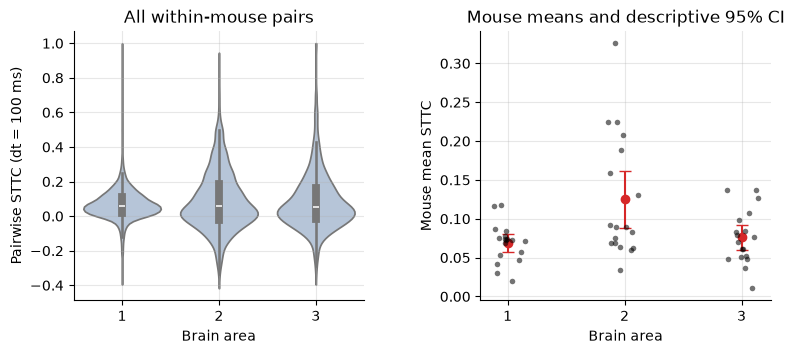

,mouse_id,brain_area,mean_sttc,median_sttc,sd_sttc,n_pairs
0,1,1,0.073990,0.075833,0.112275,1711
1,1,2,0.131186,0.112018,0.165846,231
2,1,3,0.048206,0.041794,0.086687,21
3,2,1,0.072215,0.083330,0.125480,780
4,2,2,0.092252,0.078735,0.145193,190
5,2,3,0.036533,0.009997,0.129085,171
6,3,1,0.073447,0.064816,0.062061,1081
7,3,2,0.064133,0.054321,0.129460,325
8,3,3,0.097973,0.080071,0.176165,66
9,4,1,0.116359,0.118707,0.081410,561


,mean_sttc,sd_mouse_means,n_mice,sem_sttc,ci95_margin_sttc,ci95_low_sttc,ci95_high_sttc,n_pairs
brain_area,,,,,,,,
1,0.068902,0.025286,18,0.005960,0.011682,0.057220,0.080584,14008
2,0.124874,0.079344,18,0.018702,0.036655,0.088219,0.161529,7632
3,0.075931,0.034933,18,0.008234,0.016138,0.059793,0.092070,3659


Descriptively strongest at 100 ms: brain area 2 (mean of mouse means = 0.124874).


In [6]:
mouse_area_summary = (
    pairs_df.groupby(["mouse_id", "brain_area"], as_index=False)
    .agg(
        mean_sttc=("sttc", "mean"),
        median_sttc=("sttc", "median"),
        sd_sttc=("sttc", "std"),
        n_pairs=("sttc", "size"),
    )
)
area_summary = (
    mouse_area_summary.groupby("brain_area")["mean_sttc"]
    .agg(mean_sttc="mean", sd_mouse_means="std", n_mice="count")
)
area_summary["sem_sttc"] = (
    area_summary["sd_mouse_means"] / np.sqrt(area_summary["n_mice"])
)
area_summary["ci95_margin_sttc"] = 1.96 * area_summary["sem_sttc"]
area_summary["ci95_low_sttc"] = (
    area_summary["mean_sttc"] - area_summary["ci95_margin_sttc"]
)
area_summary["ci95_high_sttc"] = (
    area_summary["mean_sttc"] + area_summary["ci95_margin_sttc"]
)
area_summary["n_pairs"] = pairs_df.groupby("brain_area").size()

if MAX_GROUPS is None:
    atomic_csv_write(mouse_area_summary, mouse_area_csv_path)
    atomic_csv_write(area_summary.reset_index(), area_summary_csv_path)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
plt.subplots_adjust(wspace=0.4)
sns.violinplot(
    data=pairs_df, x="brain_area", y="sttc", cut=0,
    density_norm="width", color="lightsteelblue", ax=axes[0],
)
axes[0].set_xlabel("Brain area")
axes[0].set_ylabel("Pairwise STTC (dt = 100 ms)")
axes[0].set_title("All within-mouse pairs")
axes[0].grid(True, linestyle="-", alpha=0.3)

sns.stripplot(
    data=mouse_area_summary, x="brain_area", y="mean_sttc",
    color="black", alpha=0.55, size=4, jitter=0.15, ax=axes[1],
)
area_positions = np.arange(len(area_summary))
axes[1].errorbar(
    area_positions, area_summary["mean_sttc"],
    yerr=area_summary["ci95_margin_sttc"],
    fmt="o", color="tab:red", markersize=6, capsize=4, linewidth=1.5,
)
axes[1].set_xlabel("Brain area")
axes[1].set_ylabel("Mouse mean STTC")
axes[1].set_title("Mouse means and descriptive 95% CI")
axes[1].grid(True, linestyle="-", alpha=0.3)
sns.despine()

if MAX_GROUPS is None:
    fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

display(mouse_area_summary)
display(area_summary)
if MAX_GROUPS is None:
    strongest_area = area_summary["mean_sttc"].idxmax()
    print(
        f"Descriptively strongest at 100 ms: brain area {strongest_area} "
        f"(mean of mouse means = {area_summary.loc[strongest_area, 'mean_sttc']:.6f})."
    )